# 01 · Análise exploratória do BreakHis (base bruta)

Exige `data/breakhis_raw.csv`, gerado por
`uv run python scripts/build_csv.py`.

Convenções: `id_paciente` numero de registro (ex. `14-22549`) e `secao` as
letras que o seguem (ex. `AB`). A **pasta** oficial (`14-22549AB`), que dá os 82
"pacientes" do artigo da base, é `id_paciente + secao`.

In [27]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

# ordem: seen (DC, F, MC, TA), unseen da meta-validação (A, LC), unseen do meta-teste (PT, PC) — D2
SUBTIPOS = ["DC", "F", "MC", "TA", "A", "LC", "PT", "PC"]
PAPEL = dict(DC="seen", F="seen", MC="seen", TA="seen", A="unseen mval", LC="unseen mval", PT="unseen mtst", PC="unseen mtst")
MAGS = [40, 100, 200, 400]

df = pd.read_csv(DATA / "breakhis_raw.csv", keep_default_na=False)  # secao vazia fica "" (não NaN)
df["pasta"] = df.id_paciente + df.secao


def show(paths, titles, ncols, size=2.6):
    """Grade de imagens (caminhos relativos a data/); None deixa a célula vazia."""
    nrows = -(-len(paths) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size * 1.5, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p, t in zip(axes.flat, paths, titles):
        if p:
            img = Image.open(DATA / p)
            img.thumbnail((350, 350))
            ax.imshow(img)
            ax.set_title(t, fontsize=8)
    plt.tight_layout()
    plt.show()


len(df)
display(df.head(3))

,path,classe,id_subtipo,des_subtipo,id_paciente,secao,magnificacao,seq,rgb_hash,pasta
0,BreaKHis_v1/histology_slides/breast/benign/SOB...,benign,A,adenosis,14-22549,AB,100,1,ea3dbf83b721b2a4a6b4c84ac482e1d1,14-22549AB
1,BreaKHis_v1/histology_slides/breast/benign/SOB...,benign,A,adenosis,14-22549,AB,100,2,43c8a4f9c16d125157511c9b68220958,14-22549AB
2,BreaKHis_v1/histology_slides/breast/benign/SOB...,benign,A,adenosis,14-22549,AB,100,3,fd0ea996a1fcfcb4d37e678f61ccf8a7,14-22549AB


## 1. Visão geral

In [13]:
pd.crosstab(df.id_subtipo, df.magnificacao, margins=True, margins_name="total").loc[SUBTIPOS + ["total"]]

magnificacao,40,100,200,400,total
id_subtipo,,,,,
DC,864,903,896,788,3451
F,253,260,264,237,1014
MC,205,222,196,169,792
TA,149,150,140,130,569
A,114,113,111,106,444
LC,156,170,163,137,626
PT,109,121,108,115,453
PC,145,142,135,138,560
total,1995,2081,2013,1820,7909


In [14]:
resumo = df.groupby("id_subtipo").agg(
    des_subtipo=("des_subtipo", "first"),
    classe=("classe", "first"),
    imagens=("path", "size"),
    pastas=("pasta", "nunique"),
    pacientes=("id_paciente", "nunique"),
).loc[SUBTIPOS]
resumo.insert(2, "papel", resumo.index.map(PAPEL))
print("pares (subtipo, pasta):", df.groupby(["id_subtipo", "pasta"]).ngroups,
      "| pastas distintas:", df.pasta.nunique(),
      "| id_paciente distintos:", df.id_paciente.nunique())
resumo

pares (subtipo, pasta): 82 | pastas distintas: 81 | id_paciente distintos: 70


,des_subtipo,classe,papel,imagens,pastas,pacientes
id_subtipo,,,,,,
DC,ductal_carcinoma,malignant,seen,3451,38,38
F,fibroadenoma,benign,seen,1014,10,7
MC,mucinous_carcinoma,malignant,seen,792,9,7
TA,tubular_adenoma,benign,seen,569,7,6
A,adenosis,benign,unseen mval,444,4,2
LC,lobular_carcinoma,malignant,unseen mval,626,5,4
PT,phyllodes_tumor,benign,unseen mtst,453,3,3
PC,papillary_carcinoma,malignant,unseen mtst,560,6,6


In [15]:
cobertura = df.groupby("pasta").magnificacao.nunique()
print("pastas sem as 4 magnificações:", (cobertura < 4).sum())

pastas sem as 4 magnificações: 0


## 2. Identificação de imagens duplicadas (Hash)

`rgb_hash` é um MD5 da **matriz RGB** de cada imagem: imagens com o mesmo conteúdo têm
o mesmo hash, mesmo com arquivos diferentes.

In [33]:
dup = df[df.duplicated("rgb_hash", keep=False)].sort_values(["rgb_hash", "id_subtipo"])
print(f"{dup.rgb_hash.nunique()} grupos de imagens repetidas, {len(dup)} arquivos envolvidos")
dup.groupby(["classe", "id_subtipo", "pasta"]).size()

125 grupos de imagens repetidas, 250 arquivos envolvidos


classe     id_subtipo  pasta   
malignant  DC          14-13412    123
           LC          14-12204      4
                       14-13412    123
dtype: int64

### paciente `14-13412` rotulado como DC **e** como LC

As 123 imagens da pasta `SOB_M_DC_14-13412` reaparecem em `SOB_M_LC_14-13412`. Os dois subtipos são malignos; podendo ser um carcinoma misto (ductal e lobular) catalogado duas vezes. Será deduplicado para analise exclusiva do paciente.

pares DC×LC idênticos: 123


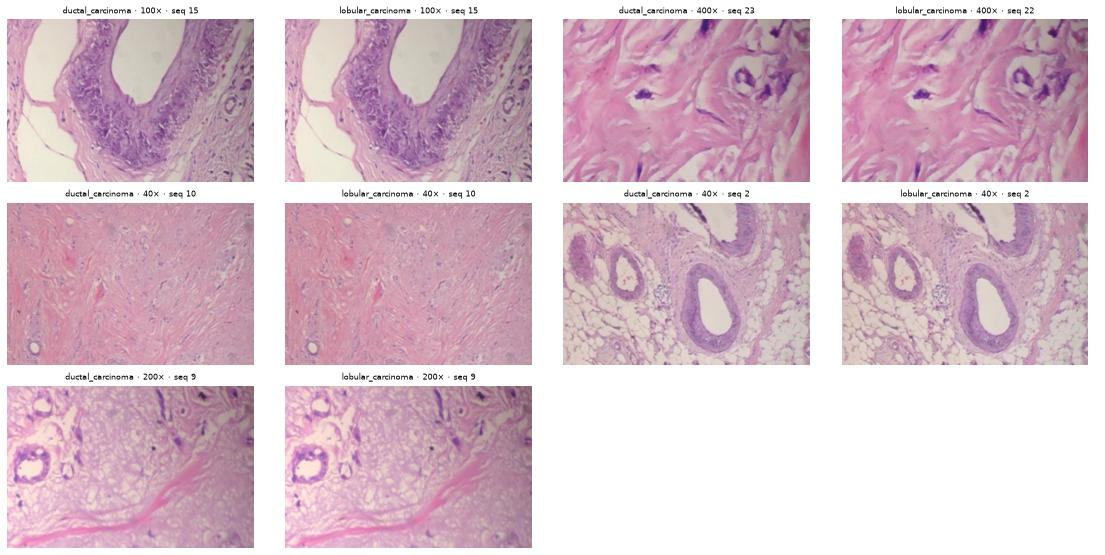

In [ ]:
par = dup[dup.pasta == "14-13412"].groupby("rgb_hash").filter(lambda g: set(g.id_subtipo) == {"DC", "LC"})
print("pares DC×LC idênticos:", par.rgb_hash.nunique())

amostra = par[par.rgb_hash.isin(par.rgb_hash.unique()[::30])]  # amostra dos pares identicos
show(amostra.path.tolist(), [f"{r.des_subtipo} · {r.magnificacao}× · seq {r.seq}" for r in amostra.itertuples()], ncols=4)

### Repetições dentro de um mesmo paciente

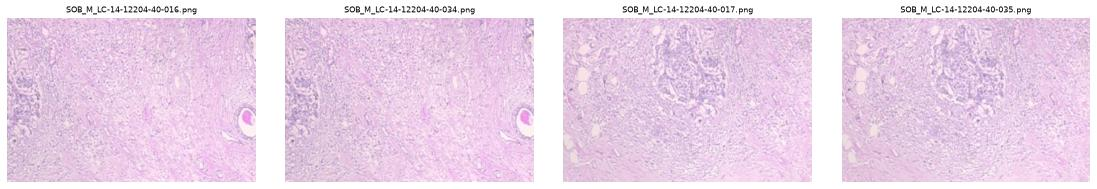

,id_subtipo,pasta,magnificacao,seq,rgb_hash
6029,LC,14-12204,40,16,021f9f964a8158a336694a35a130c93b
6032,LC,14-12204,40,34,021f9f964a8158a336694a35a130c93b
6030,LC,14-12204,40,17,3c070a5dc8db9cf036a2d7945397172f
6033,LC,14-12204,40,35,3c070a5dc8db9cf036a2d7945397172f


In [19]:
outros = dup[dup.pasta != "14-13412"]
show(outros.path.tolist(), [Path(p).name for p in outros.path], ncols=4)
outros[["id_subtipo", "pasta", "magnificacao", "seq", "rgb_hash"]]

## 3. pastas diferentes com o mesmo `id_paciente`

O README da base BreakHis define um paciente como uma combinação de id de paciente + seção (`<PATIENT_ID>::=<NUMBER><SEC>`), sem devida documentação do que caracteriza uma seção. Para a quantificação de vazamentos, um paciente será definido somente pelo seu ID. Seções diferentes com um mesmo id_paciente serão consideradas como um paciente único, assumindo que uma seção pode ser um fragmento da mesma lâmina.

In [ ]:
pastas = df.groupby(["id_paciente", "id_subtipo", "pasta"]).size().rename("imagens").reset_index()
multi = pastas[pastas.groupby("id_paciente").pasta.transform("nunique") > 1]

multi.assign(varios_subtipos=multi.groupby("id_paciente").id_subtipo.transform("nunique") > 1)

,id_paciente,id_subtipo,pasta,imagens,varios_subtipos
16,14-14134,F,14-14134,142,False
17,14-14134,F,14-14134E,94,False
21,14-15570,LC,14-15570,201,False
22,14-15570,LC,14-15570C,125,False
28,14-16184,TA,14-16184,132,False
29,14-16184,TA,14-16184CD,124,False
42,14-18842,MC,14-18842,62,False
43,14-18842,MC,14-18842D,64,False
46,14-19979,MC,14-19979,98,False
47,14-19979,MC,14-19979C,62,False


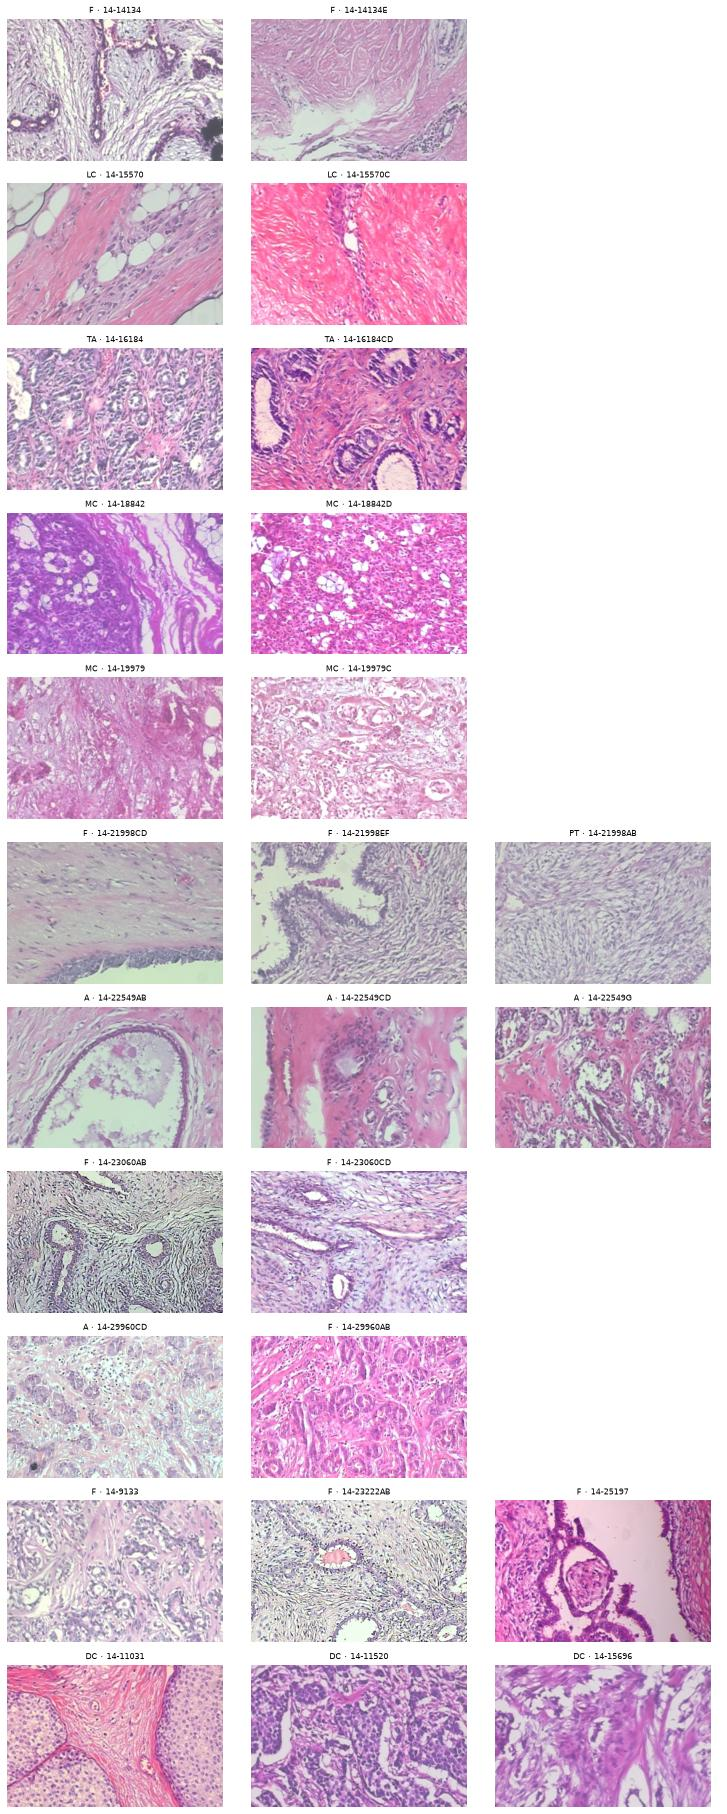

In [ ]:
rng = np.random.default_rng(0)
m100 = df[df.magnificacao == 100]

controle = pastas[~pastas.id_paciente.isin(multi.id_paciente)]  # controle: pacientes com uma única pasta

linhas = [g.pasta.tolist() for _, g in multi.groupby("id_paciente")]
linhas += [rng.choice(controle[controle.id_subtipo == s].pasta.unique(), 3, replace=False).tolist() for s in ["F", "DC"]]
paths, titles = [], []
for linha in linhas:
    for col in range(3):
        r = m100[m100.pasta == linha[col]].iloc[0] if col < len(linha) else None
        paths.append(None if r is None else r.path)
        titles.append("" if r is None else f"{r.id_subtipo} · {r.pasta}")
show(paths, titles, ncols=3, size=2.3)

## 4. Imagens por paciente × magnificação

Número de pacientes (`id_paciente`) e mínimo, mediana e máximo de imagens por paciente,
por subtipo e magnificação.

In [35]:
n = df.groupby(["id_subtipo", "id_paciente", "magnificacao"]).size()
t = n.groupby(["id_subtipo", "magnificacao"]).agg(n="count", min="min", mediana="median", max="max")
t = t.unstack("magnificacao").reindex(SUBTIPOS).swaplevel(axis=1)
t[[(m, c) for m in MAGS for c in ["n", "min", "mediana", "max"]]]

magnificacao 40                  100                  200                 400  \
               n min mediana max   n min mediana  max   n min mediana max   n   
id_subtipo                                                                      
DC            38   1    23.0  39  38  10    22.5   42  38   9    21.5  62  38   
F              7  17    26.0  68   7  15    33.0   64   7  17    34.0  66   7   
MC             7  15    29.0  46   7  12    38.0   50   7  14    23.0  47   7   
TA             6  12    16.0  74   6  14    16.5   71   6  12    16.5  58   6   
A              2  15    57.0  99   2  13    56.5  100   2  16    55.5  95   2   
LC             4  20    27.0  82   4  17    32.0   89   4  18    30.0  85   4   
PT             3  13    38.0  58   3  16    39.0   66   3  14    42.0  52   3   
PC             6  17    22.0  35   6  16    21.5   38   6  14    20.0  33   6   

magnificacao                  
             min mediana max  
id_subtipo                    
DC             8    21.0  38  
F             17    33.0  60  
MC            11    25.0  39  
TA            14    15.5  53  
A             17    53.0  89  
LC            17    25.0  70  
PT            17    39.0  59  
PC            13    19.5  36

## 5. Amostra de Paciente por Magnificação e Imagem por Subtipo

Primeiro, um paciente nas 4 magnificações; depois, 4 imagens de
um mesmo paciente (linha de cima) contra 4 pacientes diferentes do mesmo subtipo
(linha de baixo), todas a 100×.

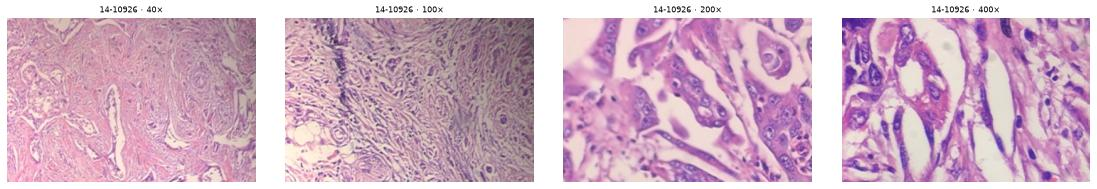

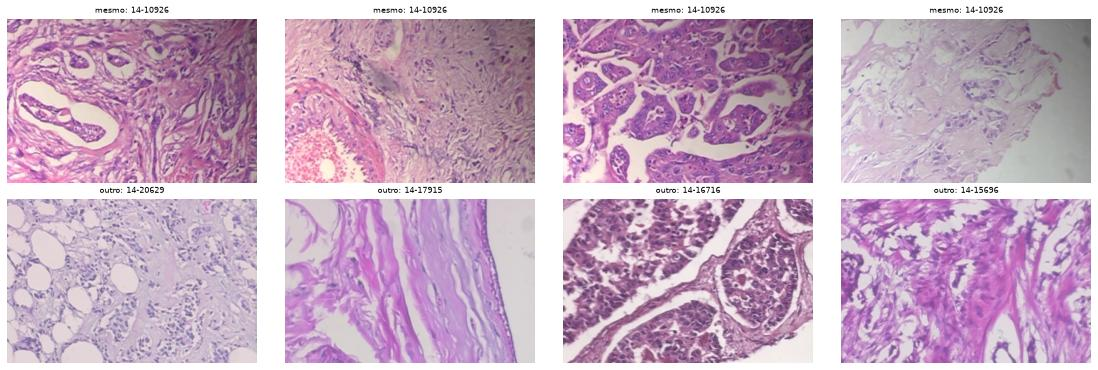

In [ ]:
p0 = df[df.id_subtipo == "DC"].id_paciente.iloc[0]

um = df[df.id_paciente == p0].groupby("magnificacao").first().reset_index()
show(um.path.tolist(), [f"{p0} · {m}×" for m in um.magnificacao], ncols=4)

mesmo = m100[m100.id_paciente == p0].sample(4, random_state=0)
outros_pac = m100[(m100.id_subtipo == "DC") & (m100.id_paciente != p0)].groupby("id_paciente").first().sample(4, random_state=0)
show(mesmo.path.tolist() + outros_pac.path.tolist(),
     [f"mesmo: {p0}"] * 4 + [f"outro: {p}" for p in outros_pac.index], ncols=4)

## 6. Tratativas em `02_clear_csv.ipynb`

-  14-13412: mesmas 123 imagens em DC e LC -> manter só em LC
- LC 14-12204: 2 pares repetidos -> deduplicar (fica a menor `seq`) 
- Pastas com o mesmo número de registro -> paciente = `id_paciente` (ignora a `secao`)
- 14-21998 (F/PT) e 14-29960 (A/F) -> descartar as imagens de F 